# What do you actually own when you buy an AI bond? The post's thread

This notebook is the **single thread for the blog post**. It follows the outline in `post_outline.md` section by section. For each section it:
- states the post's claims in plain language;
- **re-checks every number against the handoff files** the analysis notebooks write (`data/*.csv`), and stops with an error if a claim no longer matches;
- shows the charts the post uses, in the order the post uses them.

It also builds the post's one new chart (§8, `charts/00_what_the_spread_pays_for.png`). Method, caveats and detail live in the analysis notebooks; each claim names the notebook § it comes from.

**The thread.** A bond's yield pays you for what you own, and for most AI bonds, what you own isn't what the headline says. The post walks one ladder, from "no AI debt" to "all AI debt": **Apple → Alphabet → Meta → Meta's SPVs → SpaceX → CoreWeave.** At each rung it asks what people think you own, what you actually own, and what the yield is paying for.

**Short answer:**
1. **Big tech (Apple, Alphabet, Meta):** the stocks see ~0bp of default risk, so their bond spreads pay for length, liquidity and new supply, not default (§3–4).
2. **Beignet/Sopaipilla:** you lent to Meta's landlord, not Meta. The ~110–125bp premium over Meta's own bonds pays you to be short Meta's option to walk away every 4 years, plus illiquidity (§5).
3. **SpaceX yields ~7.2% (vs. ~4.7% on a Treasury).** You're buying three things: GPU scarcity lasting, SpaceX finding $190–455B of new money, and a backstop (Starlink, a ~$1.9T stock) that is economic, not legal. $100 becomes ~$139 by 2031 if repaid vs. ~$125 in Treasuries, so you need ~80–89% confidence (§6).
4. **CoreWeave yields ~15%.** The only bond whose spread is mostly default risk, and the stock sees about as much (a little more). You're buying one thing: GPU scarcity lasting to 2031, with no other business behind it. $100 becomes ~$186 if repaid; it's worth it if you put the odds of full repayment above ~40–60%. Selling stock is a real backstop for the 2028 maturities (~26% of the company at $48.73), but it shrinks as the stock falls with GPU prices, so it isn't a second, separate safety net (§7, 08 §5).
5. **Put together:** for every AI bond but one, the yield isn't paying for default (§8, `00_what_the_spread_pays_for.png`).
6. **For entertainment, trades that express a view** (§9, 09 §9; options at the Nov 9 close, bonds Nov 10; "yield" = yearly return on the cash put up):
   - *Build your own bond:* Treasuries + sold $20/$10 put spreads earn ~14.9% on CoreWeave (bond 14.6%) but lose below ~$16; on SpaceX you have to insure against a ~60% fall ($60/$30) to beat the bond's 7.2% (~8.2%).
   - *Dilution, not default*: CoreWeave's 2030 notes + a $20 put − a $90 call: ~17% a year if nothing changes, ~+$130 even in a default. Reader version: an iron condor at ~13% a year between $10 and $90.
   - *Solvent but overvalued*: Treasuries + a $100/$25 put spread loses at most ~$725 and makes ~$6,700 (24% a year) at $350B. The seagull earns ~2.3% a year if nothing changes.

| § | Post section | Question | Charts |
|---|---|---|---|
| 1 | Background | Where is the credit market? | `02_oas_by_rating` |
| 2 | Methods | How do you get from a bond price to "default risk"? | (table) |
| 3 | Apple & Alphabet | What does a control look like? | `02_spread_vs_rating` |
| 4 | Meta | Is Meta's spread about default? | `03_implied_default_odds` |
| 5 | Beignet / Sopaipilla | What does an SPV holder own? | `05_meta_vs_beignet`, `07_meta_exposure`, `07_spv_vs_meta_scenarios` |
| 6 | SpaceX | At ~7%, what are you buying? | `06_spacex_segments`, `06_spacex_runway` |
| 7 | CoreWeave | At ~15%, is it worth it, what are you buying, and could selling stock rescue the bonds? | `03_what_the_yield_buys`, `08_equity_backstop`, `06_risk_scatter`, `08_rent_vs_contracts`, `08_renewal_breakeven`, `08_funding_mix` |
| 8 | Synthesis | What is each spread paying for? | **`00_what_the_spread_pays_for`** (new, built here) |
| 9 | Trades (for entertainment) | How do you bet on a view, and how does a reader do it without the 144A bond? | `09_build_your_own_bond`, `09_coreweave_trades`, `09_coreweave_payoffs`, `09_spacex_trades`, `09_spacex_payoffs`, `09_how_to_build_it` |

**Analysis notebooks, in reading order** (each opens with its own short answer and roadmap):

| # | Notebook | Question | Feeds |
|---|---|---|---|
| 01 | `01_data_pull` | Fetch and cache Treasuries, credit spreads, stocks, options, SEC filings | all |
| 02 | `02_spreads` | What does the market charge each bond vs. its rating? | 03, 05, 07 |
| 03 | `03_implied_default` | What default odds do those spreads imply, and *when*? | 05, 06 |
| 04 | *(not built)* | CoreWeave's GPU collateral vs. the debt. Largely covered by 08 §3 | — |
| 05 | `05_equity_vs_bond` | Do the stock and the bonds see the same risk? | 06 |
| 06 | `06_fundamentals` | Can they pay, and when? What do the options say? | this |
| 07 | `07_meta_spvs` | What does a Beignet/Sopaipilla holder own? | — |
| 08 | `08_neoclouds` | What does CoreWeave's survival depend on? Could selling stock save the bonds? Nebius for contrast | this |
| 09 | `09_trades` | Trades that express a view on CoreWeave and SpaceX, priced from Nov 9 options and Nov 10 TRACE | this |
| 10 | `10_gpu_unit_economics` | Per-GPU economics, chip lives, and how CoreWeave gets off its razor's edge (§9, `10_escape.png`) | this |

**Inputs:** `data/spreads.csv` (02), `data/implied_pd.csv`, `data/forward_pd.csv` and `data/yield_buys.csv` (03), `data/merton_inputs.csv` and `data/equity_vs_bond.csv` (05), `data/fundamentals.csv` and `data/merton_iv.csv` (06), `data/neocloud_inputs.csv` and `data/equity_backstop.csv` (08), `data/crash_odds.csv` (06), `data/trades.csv`, `data/trade_quotes.csv` and `data/trade_profiles.csv` (09), `data/fred/` (01). Prices are TRACE last trades from **Nov 10, 2026**, options from the Nov 9 close; filings run through Oct 26 (CoreWeave's Q3 release, Nov 10, is in 10 §8–9 only).

**Output:** `charts/00_what_the_spread_pays_for.png`.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from common import load, source_note, treasury_yield, BOND, EQUITY, MUTED, INK2

AS_OF = pd.read_csv('data/spreads.csv').query("kind == 'trade'").as_of.max()   # latest TRACE quote date
s = pd.read_csv('data/spreads.csv')
now = s[(s.as_of == AS_OF) & (s.kind == 'trade')].set_index('bond_id')
issue = s[s.kind == 'issue'].set_index('bond_id')
pd5 = pd.read_csv('data/implied_pd.csv').set_index('bond_id')
fwd = pd.read_csv('data/forward_pd.csv')
evb = pd.read_csv('data/equity_vs_bond.csv').set_index('issuer')
iv = pd.read_csv('data/merton_iv.csv').set_index('issuer')['implied vol, 5y']   # 06 §7: stock-implied 5y spread, option-implied vol
fund = pd.read_csv('data/fundamentals.csv', index_col=0)
neo = pd.read_csv('data/neocloud_inputs.csv').set_index('item').value
min_ = pd.read_csv('data/merton_inputs.csv').set_index('issuer')
eqb = pd.read_csv('data/equity_backstop.csv', index_col=0)                     # 08 §5: share of company sold, by price
crash = pd.read_csv('data/crash_odds.csv').query("issuer == 'CoreWeave'").iloc[-1]   # 06 §8, Jan 2029
trades = pd.read_csv('data/trades.csv').set_index(['ticker', 'trade', 'scenario']).pnl   # 09: P&L by trade and scenario, Jan 2029
tq = pd.read_csv('data/trade_quotes.csv').query('as_of == as_of.max()').set_index('bond_id')   # 09: TRACE closes the trades are priced from (latest date)
tprof = pd.read_csv('data/trade_profiles.csv').set_index(['ticker', 'trade'])            # 09 §7: reader trades' max gain/loss and break-evens
buys = pd.read_csv('data/yield_buys.csv')                                          # 03 §7: $ by Oct 2031 per $100

def check(rows):
    """rows: (claim as written in the post, computed value, low, high). Fails if any value falls outside what the wording allows."""
    t = pd.DataFrame(rows, columns=['post says', 'data', 'low', 'high'])
    t['ok'] = t.data.between(t.low, t.high)
    display(t.style.format({'data': '{:,.3g}', 'low': '{:,.3g}', 'high': '{:,.3g}'}).hide(axis='index'))
    assert t.ok.all(), f"claims out of date: {list(t[~t.ok]['post says'])}"

excess_change = lambda b: now.loc[b, 'excess'] - issue.loc[b, 'excess']

## 1 · Background: where is the credit market?

**Post claim.** Investment grade is calm and junk isn't. From Aug 22 to Nov 9, the IG average barely moved (81 → 91bp, mid-range for the last 3 years), while BB widened ~40bp, B ~60bp and CCC ~270bp (~1,040 → ~1,310bp). CoreWeave's notes trade down there [02 §1].

*Corrected Oct 31:* 02 previously said IG was "near 3-year lows" and that BB and B "barely moved". The checks below found both wrong, and 02 and the plan were fixed.

In [2]:
oas = {k: load(sid).dropna() for k, sid in {'IG': 'BAMLC0A0CM', 'BB': 'BAMLH0A1HYBB', 'B': 'BAMLH0A2HYB', 'CCC': 'BAMLH0A3HYC'}.items()}
then = lambda k: oas[k].loc[:'2026-08-22'].iloc[-1] * 100
last = lambda k: oas[k].iloc[-1] * 100
ig3y = oas['IG'].loc['2023-10-22':]
check([('IG on Aug 22 ~81bp', then('IG'), 80, 82), ('IG now ~91bp', last('IG'), 90, 92),
       ('IG mid-range for 3 years (percentile)', (ig3y < ig3y.iloc[-1]).mean(), 0.3, 0.7),
       ('BB widened ~40bp', last('BB') - then('BB'), 37, 47), ('B widened ~60bp', last('B') - then('B'), 55, 65),
       ('CCC ~1,040bp on Aug 22', then('CCC'), 1000, 1080), ('CCC ~1,310bp now', last('CCC'), 1290, 1330)])

post says,data,low,high,ok
IG on Aug 22 ~81bp,81,80,82,True
IG now ~91bp,91,90,92,True
IG mid-range for 3 years (percentile),0.639,0.3,0.7,True
BB widened ~40bp,42,37,47,True
B widened ~60bp,62,55,65,True
"CCC ~1,040bp on Aug 22",1.04e+03,1e+03,1.08e+03,True
"CCC ~1,310bp now",1.31e+03,1.29e+03,1.33e+03,True


![Investment grade is calm. Junk isn't. Credit spreads by rating, last 3 years (02 §1)](charts/02_oas_by_rating.png)
*`charts/02_oas_by_rating.png`: Investment grade is calm. Junk isn't. Credit spreads by rating, last 3 years (02 §1)*

## 2 · Methods: how do you get from a bond price to "default risk"?

The post leans on a few terms. This section defines each one once, with a worked example on real bonds, so the later sections can use them without a detour.

**Yield.** The return per year you earn if you buy at today's price and every payment arrives. CoreWeave's 9.75% 2031 notes cost 82.00¢ on the dollar. You collect $9.75 a year per $100 of face value plus $100 in 2031, which works out to **~15.1% a year**. The coupon (9.75%) is what the company promised when it borrowed. The yield (15.1%) is what a buyer earns today, higher because the price has fallen.

**Spread.** The yield minus the yield on a US Treasury maturing at about the same time. It's the extra the market demands for lending to this company instead of the government: 15.1% − 4.7% = **10.4 percentage points**. Bond people count in **basis points (bp)**: 1bp = 0.01 percentage point, so 10.4 points = 1,041bp, and 93bp = 0.93 points.

**Default spread.** The part of the spread that pays for the losses you expect from defaults. The rest pays for everything else: a bond that's hard to sell, a long maturity, a flood of new bonds from the same sector, being outranked by other lenders. **You can't observe the split directly.** We estimate it two ways, and the gap between them is the post's main tool.

**1. From the bond: the credit triangle → "bond-implied default odds"** (03 §1). Assume the *whole* spread pays for defaults. If you lose (1 − R) of your money when a default happens (R is the recovery rate, 40% for an unsecured bond), the spread has to cover odds × loss:
- annual odds ≈ spread ÷ (1 − R). CoreWeave: 10.4% ÷ 0.6 = **~17.4% a year**.
- over 5 years: 1 − (1 − 17.4%)⁵ = **~61%**.

That's an *upper bound*, because some of the spread pays for other things. Insurance analogy: premium ≈ chance of a claim × size of the claim. If you think the premium is all claims, you'll overestimate the claims.

**2. From the stock: Merton → "stock-implied default spread"** (05 §2, 06 §7). Shareholders are paid last, so a share works like the equity in a house with a mortgage: worth something only while the house is worth more than the loan. Three numbers give how likely it is the "house" (the company's assets) ends up worth less than its debt in 5 years:
- the stock market value;
- the debt;
- how much the stock is expected to swing, read from option prices ("implied volatility").

Turn that likelihood into the extra yield a lender would need to break even, and you have the **stock-implied default spread**: the default risk the stock market sees, in the same units as the bond spread. CoreWeave: shares worth ~$26.9B, debt $35.55B, options pricing ~87% swings a year (06 §7) → **~1,136bp**, a little more than its bond's 1,041bp. So for CoreWeave, the stock says the whole spread is default risk. For Meta, the stock says ~0.6bp of its 93bp is.

**Wherever the post says "default risk the stock sees", it means #2. "Implied default odds" means #1.**

**Beware the rating** (the "Beware Adjusted EBITDA" box): every bond's price implies far more defaults than its rating's history, even Apple's (~20–37×) (03 §1–3). That's the price of illiquidity and risk, not a forecast. So the post compares bonds **within the same rating**, or **the same bond over time**.

**The full yields** (Nov 10 TRACE). Spreads are the cleanest comparison, but readers think in yields, so the post quotes both:

In [3]:
cw31, mt31 = now.loc['CRWV_9.75_2031'], now.loc['META_4.55_2031']
show = now.sort_values('years')[['issuer', 'years', 'price', 'yield', 'tsy', 'g_spread']].rename(
    columns={'years': 'years left', 'yield': 'yield %', 'tsy': 'Treasury %', 'g_spread': 'spread (bp)'})
display(show.style.format({'years left': '{:.1f}', 'price': '{:.2f}', 'yield %': '{:.2f}', 'Treasury %': '{:.2f}', 'spread (bp)': '{:,.0f}'}))

a = (cw31.g_spread / 1e4) / (1 - 0.4)
check([('CoreWeave 2031 yields ~15.1%', cw31['yield'], 15.05, 15.15), ('Treasury ~4.7%', cw31.tsy, 4.62, 4.72),
       ('spread 1,041bp', cw31.g_spread, 1039, 1043), ('~17.4% a year', a, 0.169, 0.179), ('~61% over 5 years', 1 - (1 - a) ** 5, 0.60, 0.62),
       ('market value ~$26.9B', min_.loc['CoreWeave', 'market cap ($bn)'], 26.8, 27.0), ('stock-implied ~1,136bp', iv['CoreWeave'], 1130, 1142),
       ('Meta stock-implied ~0.6bp of ~93bp', iv['Meta'], 0.5, 0.7), ('Meta 2031 ~93bp', mt31.g_spread, 92, 94),
       ('~5y yields: Apple ~4.9%', now.loc['AAPL_4.20_2030', 'yield'], 4.85, 4.95), ('Alphabet ~5.3%', now.loc['GOOG_4.100_2031', 'yield'], 5.25, 5.35),
       ('Meta ~5.6%', mt31['yield'], 5.55, 5.65), ('SpaceX ~7.2%', now.loc['SPCX_5.350_2031', 'yield'], 7.15, 7.25),
       ('CoreWeave ~14.4-15.1% (low)', now[now.issuer == 'CoreWeave']['yield'].min(), 14.3, 14.4),
       ('SPVs ~7.3-7.7% (Beignet)', now.loc['BEIGNET_6.581_2049', 'yield'], 7.25, 7.35), ('SPVs (Sopaipilla)', now.loc['SOPAIPILLA_2048', 'yield'], 7.65, 7.75),
       ('Apple: price implies ~20-37x its rating history (low)', pd5.loc[pd5.index.str.startswith('AAPL'), 'x_history'].min(), 19, 21),
       ('Apple: ~20-37x (high)', pd5.loc[pd5.index.str.startswith('AAPL'), 'x_history'].max(), 36, 38)])

,issuer,years left,price,yield %,Treasury %,spread (bp)
bond_id,,,,,,
AAPL_4.20_2030,Apple,3.5,97.73,4.91,4.60,31
CRWV_9.25_2030,CoreWeave,3.6,85.50,14.62,4.61,"1,002"
CRWV_9.00_2031,CoreWeave,4.2,81.75,14.98,4.64,"1,034"
GOOG_4.100_2031,Alphabet,4.3,95.39,5.32,4.64,69
META_4.55_2031,Meta,4.5,95.97,5.57,4.65,93
SPCX_5.350_2031,SpaceX,4.7,92.74,7.20,4.66,255
CRWV_9.75_2031,CoreWeave,4.9,82.00,15.08,4.67,"1,041"
CRWV_9.625_2032,CoreWeave,5.7,82.00,14.35,4.70,965
SPCX_5.650_2033,SpaceX,6.7,91.17,7.34,4.75,260


post says,data,low,high,ok
CoreWeave 2031 yields ~15.1%,15.1,15.1,15.2,True
Treasury ~4.7%,4.67,4.62,4.72,True
"spread 1,041bp",1.04e+03,1.04e+03,1.04e+03,True
~17.4% a year,0.174,0.169,0.179,True
~61% over 5 years,0.614,0.6,0.62,True
market value ~$26.9B,26.9,26.8,27,True
"stock-implied ~1,136bp",1.14e+03,1.13e+03,1.14e+03,True
Meta stock-implied ~0.6bp of ~93bp,0.601,0.5,0.7,True
Meta 2031 ~93bp,92.6,92,94,True
~5y yields: Apple ~4.9%,4.91,4.85,4.95,True


**What this shows:** at the same ~5-year maturity, only two bonds pay much more than a Treasury's ~4.7%: **SpaceX at ~7.2% and CoreWeave at ~15%.** Apple, Alphabet and Meta pay 4.9–5.6%. The Meta SPVs (~7.3–7.7%) and Meta's 2056 bond (~7.2%) look as rewarding as SpaceX, but they're 15–30-year bonds, and most of that is the higher long-term Treasury rate (~5.3%). That's why §6–7 ask "is it worth it?" only for SpaceX and CoreWeave.

## 3 · Apple and Alphabet: the control, and the control that isn't

**Post claims** [02 §3, §5, §6C; 06 §2]:
- Apple trades *through* its AA average (~−36bp on the 2030s) and has tightened since issue while every AI spender widened.
- ~5-year bonds pay Apple ~31bp and Alphabet ~69bp over Treasuries: yields of ~4.9% and ~5.3%, against ~4.7% on the Treasury.
- Both could repay all their debt in under a year if they stopped growing (0.7 / 0.8 years).
- Alphabet borrowed ~$51.8B in H1 2026 *and* sold stock (Q2 10-Q; plan §1 finding 4, not in a handoff file).

In [4]:
check([('Apple 2030 vs AA average ~-36bp', now.loc['AAPL_4.20_2030', 'excess'], -37, -35),
       ('Apple 2030 tightened since issue (~-8bp)', excess_change('AAPL_4.20_2030'), -9, -7),
       ('Apple 2035 tightened since issue (~-20bp)', excess_change('AAPL_4.75_2035'), -21, -19),
       ('Apple ~5y spread ~31bp', now.loc['AAPL_4.20_2030', 'g_spread'], 30, 32),
       ('Alphabet ~5y spread ~69bp', now.loc['GOOG_4.100_2031', 'g_spread'], 68, 70),
       ('Apple repays in ~0.7 years paused', fund.loc['Apple', 'years to repay debt if paused'], 0.65, 0.75),
       ('Alphabet ~0.8 years', fund.loc['Alphabet', 'years to repay debt if paused'], 0.75, 0.85)])

post says,data,low,high,ok
Apple 2030 vs AA average ~-36bp,-35.9,-37,-35,True
Apple 2030 tightened since issue (~-8bp),-7.87,-9,-7,True
Apple 2035 tightened since issue (~-20bp),-20.2,-21,-19,True
Apple ~5y spread ~31bp,31.1,30,32,True
Alphabet ~5y spread ~69bp,68.7,68,70,True
Apple repays in ~0.7 years paused,0.678,0.65,0.75,True
Alphabet ~0.8 years,0.807,0.75,0.85,True


![Same rating, very different price. Each bond's spread vs. its rating average (02 §3)](charts/02_spread_vs_rating.png)
*`charts/02_spread_vs_rating.png`: Same rating, very different price. Each bond's spread vs. its rating average (02 §3)*

## 4 · Meta: the bond really is Facebook, and it isn't paying for default

**Post claims** [02 §5; 03 §3, §6; 05 §3; 06 §2, §7]:
- Meta's stock implies ~0.6bp of default spread (the default risk the stock sees, §2); its ~5-year bond pays ~93bp, a ~5.6% yield.
- The implied default rate rises from ~1% a year now to ~3.6% a year in the 2050s (back-loaded).
- Meta 2056 pays ~+131bp over the AA average, +51bp more than at issue.
- Meta's long bonds price at ~3× an average AA's default odds.
- Meta could repay its debt in ~0.8 years at the pause test.

In [5]:
m = fwd[fwd.issuer == 'Meta']['annual odds']
check([('Meta stock-implied ~0.6bp', iv['Meta'], 0.5, 0.7),
       ('Meta ~5y bond ~93bp', now.loc['META_4.55_2031', 'g_spread'], 92, 94),
       ('Meta forward odds start ~1%/yr', m.iloc[0], 0.0095, 0.0105),
       ('...rise to ~3.6%/yr', m.iloc[-1], 0.0355, 0.0365),
       ('Meta 2056 ~+131bp over AA', now.loc['META_6.30_2056', 'excess'], 130, 132),
       ('Meta 2056 +51bp since issue', excess_change('META_6.30_2056'), 50, 52),
       ('Meta long bonds ~3x an AA (2056)', pd5.loc['META_6.30_2056', 'x_bucket'], 2.8, 3.2),
       ('Meta ~0.8 years paused', fund.loc['Meta', 'years to repay debt if paused'], 0.75, 0.85)])

post says,data,low,high,ok
Meta stock-implied ~0.6bp,0.601,0.5,0.7,True
Meta ~5y bond ~93bp,92.6,92,94,True
Meta forward odds start ~1%/yr,0.00994,0.0095,0.0105,True
...rise to ~3.6%/yr,0.0357,0.0355,0.0365,True
Meta 2056 ~+131bp over AA,131,130,132,True
Meta 2056 +51bp since issue,50.6,50,52,True
Meta long bonds ~3x an AA (2056),2.82,2.8,3.2,True
Meta ~0.8 years paused,0.821,0.75,0.85,True


![The rating is the prior; the price is the posterior. Market-implied 5-year default odds vs. rating peers and history (03 §3)](charts/03_implied_default_odds.png)
*`charts/03_implied_default_odds.png`: The rating is the prior; the price is the posterior. Market-implied 5-year default odds vs. rating peers and history (03 §3)*

## 5 · Beignet and Sopaipilla: you lent money to Meta's landlord

**Post claims checked here** [02 §5; 03 §3; 05 §3, §5]:
- Beignet trades ~+126bp over the A average, slightly tighter than at issue (−11bp). Sopaipilla has tightened too (~−9bp).
- Implied 5-year odds of ~23% / ~26%, about 4× an average A and ~330× what Meta's stock implies for Meta.
- Beignet last traded at ~92.2 on Nov 10, a ~7.3% yield (Sopaipilla ~7.7%), vs. ~5.3% on a long Treasury.

**Post claims that live only in 07 and 05** (checked against those notebooks' outputs on Nov 10, but not handed off as data):
- ~15-year average life; ~250–265bp over Treasuries on an amortizing basis (07 §2).
- ~110–125bp structure premium over Meta's own curve, narrowed since issue (~149bp) (07 §3).
- ~$0.5B a year buys ~$40B off balance sheet; ~$92B of rent if renewed (07 §4).
- An all-default reading implies ~35% odds over the bonds' life (07 §5).
- −30 to −58 per $100 if a healthy Meta walks at renewal 1; 56–100% recovery if Meta is sick (07 §6).
- All of Beignet's ~8-point fall is rates (05 §5).

In [6]:
check([('Beignet ~+126bp over A', now.loc['BEIGNET_6.581_2049', 'excess'], 125, 127),
       ('Beignet ~-11bp since issue', excess_change('BEIGNET_6.581_2049'), -12, -10),
       ('Sopaipilla ~-10bp since issue', excess_change('SOPAIPILLA_2048'), -11, -9),
       ('Beignet 5y odds ~23%', pd5.loc['BEIGNET_6.581_2049', 'pd_5y'], 0.222, 0.232),
       ('Sopaipilla 5y odds ~26%', pd5.loc['SOPAIPILLA_2048', 'pd_5y'], 0.255, 0.265),
       ('SPVs ~4x an average A (Beignet)', pd5.loc['BEIGNET_6.581_2049', 'x_bucket'], 3.6, 4.4),
       ('Beignet ~330x Meta stock-implied odds', evb.loc['Meta (SPV)', 'bond 5y odds'] / evb.loc['Meta (SPV)', 'stock 5y odds'], 290, 370),
       ('Beignet price ~92.2', now.loc['BEIGNET_6.581_2049', 'price'], 92.1, 92.3)])

post says,data,low,high,ok
Beignet ~+126bp over A,126,125,127,True
Beignet ~-11bp since issue,-10.7,-12,-10,True
Sopaipilla ~-10bp since issue,-9.43,-11,-9,True
Beignet 5y odds ~23%,0.227,0.222,0.232,True
Sopaipilla 5y odds ~26%,0.264,0.255,0.265,True
SPVs ~4x an average A (Beignet),3.72,3.6,4.4,True
Beignet ~330x Meta stock-implied odds,333,290,370,True
Beignet price ~92.2,92.2,92.1,92.3,True


![Beignet's record low was a rates story. Meta stock vs. Beignet, and the rates-only path (05 §5)](charts/05_meta_vs_beignet.png)
*(Optional in the post.)* *`charts/05_meta_vs_beignet.png`: Beignet's record low was a rates story. Meta stock vs. Beignet, and the rates-only path (05 §5)*

![What Meta reports vs. what it's on the hook for (07 §4)](charts/07_meta_exposure.png)
*(Optional in the post.)* *`charts/07_meta_exposure.png`: What Meta reports vs. what it's on the hook for (07 §4)*

![Beignet: loss if a healthy Meta walks vs. extra coupon earned over Meta (07 §6)](charts/07_spv_vs_meta_scenarios.png)
*`charts/07_spv_vs_meta_scenarios.png`: Beignet: loss if a healthy Meta walks vs. extra coupon earned over Meta (07 §6)*

## 6 · SpaceX at ~7%: what are you buying?

**The price.** The 2031 notes yield **~7.2%** (the 2046 and 2056 bonds ~8.0%), against ~4.7% on a Treasury. Put $100 in today and you have **~$139 by Oct 2031** if SpaceX pays in full, vs. **~$125** in Treasuries. A default along the way leaves ~$40–70. **So the extra ~2.5 points a year are worth it only if you're ~80–89% sure of being repaid** (03 §7). SpaceX's BBB bonds already pay more than the average BB (junk) bond: ~255bp vs. ~200bp.

**What you own** (indenture, plan §7): an unsecured promise from the parent company, SpaceX itself, with **no subsidiary guarantees, no change-of-control put**, and a lien covenant whose carve-outs let new GPU debt be secured ahead of you.

**What you're buying is three bets:**
1. **GPU scarcity lasts (the same bet as CoreWeave).** The AI segment is 84% of capex (~$20B a year earned vs. ~$66B spent) and sells close to the spot price. Its $63B backlog is 67% due within a year, and consensus prices its compute at about half of management's (06 §4, §6). If GPU rents fall the way H100s' did, the build earns less than planned.
2. **SpaceX keeps finding new money.** Every path that keeps buying GPUs needs new money before the July 2031 notes mature: by Dec 2027 on consensus, mid-2029 at the Q3 pace. The guided build needs ~$190–455B of outside money by end-2028 (06 §5–6). The first ~$40B (Apollo) is a lease where the lessor *owns* the GPUs, which puts it ahead of you on them.
3. **The backstop is real, but it's economic, not legal.** Starlink earns ~$14B a year against ~$6B of capex. If SpaceX stops buying GPUs, it never runs out of money (06 §4–5). The stock is worth ~$1.9T against $38B of debt, so selling shares is always an option. That's why the stock sees **~1bp** of default risk (06 §7). But nothing in the notes ties Starlink's cash or the stock to *you*: no subsidiary guarantees, and new lenders can be secured ahead of you.

**So the ~2.5 points over Treasuries pay for bets 1–2 going wrong *after* the line in front of you has grown.** Default is unlikely, because SpaceX can always stop or sell stock. But if it happens, it happens after $100B+ of new secured money, which means a low recovery. Since issue the 2036s have cheapened +108bp against their rating bucket, more than any other bond we track (02 §5).

**Also checked here** [02 §5; 03 §3, §6; 06 §1–2]: $89.9B of cash vs. $38.0B of debt; a flat bond curve at ~3.5–4% a year from day one; ~20–21% implied 5-year odds, ~2× an average BBB; ~1.6 years to repay paused. **From 06 only** (checked against its outputs): the segment, runway and outside-money figures above; the Apollo lease (~$40B, 8-K Oct 26).

In [7]:
sx = fwd[fwd.issuer == 'SpaceX']['annual odds']
sx_pd = pd5.loc[pd5.index.str.startswith('SPCX'), 'pd_5y']
sb = buys[buys.bond == 'SPCX_5.350_2031']
bb = load('BAMLH0A1HYBB').dropna().loc[:AS_OF].iloc[-1] * 100
check([('SpaceX 2031 yields ~7.2%', now.loc['SPCX_5.350_2031', 'yield'], 7.15, 7.25),
       ('2046/2056 ~8.0%', now.loc[['SPCX_6.600_2046', 'SPCX_6.650_2056'], 'yield'].mean(), 7.95, 8.1),
       ('$139 if repaid', sb['$ if repaid'].iloc[0], 138, 140), ('$125 in Treasuries', sb.treasury.iloc[0], 124.8, 125.8),
       ('a default leaves ~$40-70 (low, R=25%)', sb[sb.recovery == 0.25]['$ if default'].min(), 38, 42),
       ('~$40-70 (high, R=40%)', sb[sb.recovery == 0.4]['$ if default'].max(), 68, 72),
       ('need ~80-89% confidence (low)', sb['need odds of repayment ≥'].min(), 0.795, 0.815),
       ('~80-89% (high)', sb['need odds of repayment ≥'].max(), 0.88, 0.895),
       ('BBB SpaceX ~255bp > average BB ~200bp', now.loc['SPCX_5.350_2031', 'g_spread'] - bb, 45, 65),
       ('stock worth ~$1.9T', min_.loc['SpaceX', 'market cap ($bn)'], 1900, 2000)])
check([('SpaceX cash $89.9B', fund.loc['SpaceX', 'cash ($bn)'], 89.8, 90.0),
       ('SpaceX debt $38.0B', fund.loc['SpaceX', 'debt ($bn)'], 37.9, 38.1),
       ('SpaceX ~5y bond ~255bp', now.loc['SPCX_5.350_2031', 'g_spread'], 254, 256),
       ('SpaceX stock-implied ~1bp', iv['SpaceX'], 0, 1.5),
       ('forward odds flat ~3.5-4%/yr (min, to 2046)', sx.iloc[:4].min(), 0.034, 0.036),
       ('forward odds flat ~3.5-4%/yr (max)', sx.iloc[:4].max(), 0.0375, 0.0415),
       ('5y odds ~20-21% (low)', sx_pd.min(), 0.19, 0.20), ('5y odds ~20-21% (high)', sx_pd.max(), 0.21, 0.22),
       ('~2x an average BBB', pd5.loc['SPCX_5.350_2031', 'x_bucket'], 1.9, 2.25),
       ('2036s +47bp at issue', issue.loc['SPCX_5.875_2036', 'excess'], 46, 48),
       ('2036s +155bp now', now.loc['SPCX_5.875_2036', 'excess'], 154, 156),
       ('2036s +108bp since issue', excess_change('SPCX_5.875_2036'), 107, 109),
       ('~1.6 years paused', fund.loc['SpaceX', 'years to repay debt if paused'], 1.55, 1.65)])

post says,data,low,high,ok
SpaceX 2031 yields ~7.2%,7.2,7.15,7.25,True
2046/2056 ~8.0%,8.03,7.95,8.1,True
$139 if repaid,139,138,140,True
$125 in Treasuries,125,125,126,True
"a default leaves ~$40-70 (low, R=25%)",38.6,38,42,True
"~$40-70 (high, R=40%)",70.1,68,72,True
need ~80-89% confidence (low),0.805,0.795,0.815,True
~80-89% (high),0.887,0.88,0.895,True
BBB SpaceX ~255bp > average BB ~200bp,54.8,45,65,True
stock worth ~$1.9T,1.94e+03,1.9e+03,2e+03,True


post says,data,low,high,ok
SpaceX cash $89.9B,89.9,89.8,90,True
SpaceX debt $38.0B,38,37.9,38.1,True
SpaceX ~5y bond ~255bp,255,254,256,True
SpaceX stock-implied ~1bp,1.16,0,1.5,True
"forward odds flat ~3.5-4%/yr (min, to 2046)",0.0353,0.034,0.036,True
forward odds flat ~3.5-4%/yr (max),0.0387,0.0375,0.0415,True
5y odds ~20-21% (low),0.195,0.19,0.2,True
5y odds ~20-21% (high),0.212,0.21,0.22,True
~2x an average BBB,2.15,1.9,2.25,True
2036s +47bp at issue,47,46,48,True


![The GPUs are the whole cash burn. SpaceX by segment: cash earned vs. upkeep and growth capex (06 §4)](charts/06_spacex_segments.png)
*`charts/06_spacex_segments.png`: The GPUs are the whole cash burn. SpaceX by segment: cash earned vs. upkeep and growth capex (06 §4)*

![Keep buying GPUs and SpaceX needs new money from ~2027. Liquidity under three spending paths (06 §5)](charts/06_spacex_runway.png)
*`charts/06_spacex_runway.png`: Keep buying GPUs and SpaceX needs new money from ~2027. Liquidity under three spending paths (06 §5)*

## 7 · CoreWeave at ~15%: is it worth it, and what are you buying?

**The price.** The unsecured notes yield **~14.4–15.1%**, against ~4.7% on a Treasury. Put $100 into the 9.75% 2031s and you have **~$186 by Oct 2031** if CoreWeave pays in full, vs. ~$125 in Treasuries. A default at *any* point before maturity loses even to Treasuries: ~$83 at 40% recovery if it defaults in 2028, ~$62 at 25%. **So it's worth it if you put the odds of full repayment above ~40–60%** (03 §7, `03_what_the_yield_buys.png`). The market's ~60% five-year default odds sit right at that line, which makes it a coin flip with a good payout.

**What you own:** CoreWeave's unsecured promise, behind ~$25B of secured debt. Not a GPU. The A3 secured loan is sized off the Meta contract, and that contract is pledged to the secured lenders (plan §1, 08 §3).

**What you're buying is one bet: GPU scarcity lasts until 2031, and there's nothing behind it.**
- **The notes mature after the contracts run out.** 80% of today's $104B backlog is used up by mid-2030 (08 §2); the notes are due Oct 2031. ~$15B of debt is due by end-2028 against $5.5B of cash. Repayment depends on re-renting old GPUs and refinancing in 2027–2031, not on today's contracts.
- **The threshold is a price.** Lenders are repaid only if old-GPU rents fall no faster than ~14% a year. H100 rents fell ~19% a year (08 §3). Booming AI demand plus a glut (the 1990s fiber story) is enough to leave you short.
- **No Starlink.** Unlike SpaceX, there's no other business to fall back on, and the stock (~$26.9B) is worth less than the debt ($35.55B at Jun 30; $46.9B at Sep 30 per the Q3 release), so selling shares can't fill a hole. The stock sees about the default risk the bonds pay for, a little more (~1,136bp vs. ~1,041bp, §2).
- **Could CoreWeave sell stock to repay you?** (08 §5, `08_equity_backstop.png`) This is the best case for the bonds, and it's partly real.
  - At $48.73 (Nov 10), covering the ~$9.5B due by end-2028 beyond its cash means selling ~26% of the company (~16% at Nvidia's $87.20). CoreWeave set up a stock-sale program in Sep 2026 (up to 35M shares, ~$1.7B at $48.73) citing debt repayment and an investment-grade goal. So a default before 2028 is far from certain.
  - It's reflexive. The stock is worth something because GPUs might stay scarce. The options market gives ~37% odds of a ≥75% fall by Jan 2029, and at that price the same raise means selling ~59%. Repaying every unsecured bond and convertible (~$21B) means ~44% today and ~76% after that fall.
  - Nobody can force it: the co-founders hold ~67% of the votes. The $10.8B of convertibles convert at $97.85–119.60, so for now they're more unsecured debt alongside yours.
  - The one lever that pays *because* demand is weak: Nvidia's $6.3B order for capacity nobody else takes, through Apr 2032 (press, Sep 2025). Real, but small next to ~$45B of rent from 2031.
  - **Net:** selling stock helps the 2030 and early-2031 notes; it doesn't change the bet for the late-2031/2032 notes. It's a second claim on the same outcome (scarcity), not an independent one.
- **Nebius is the contrast:** the same business, funded ~34% by lenders vs. ~71% at CoreWeave, with cash ≈ debt and convertibles at 1.25–2.6% (08 §4).

**Also checked here** [02 §3; 03 §3; 06 §1–2; 08 inputs]: ~615–690bp over the single-B average; ~60% implied 5-year odds, ~2.2–2.4× an average B and above CCC's historical ~46%; ~$2.7B of run-rate operating cash vs. ~$6.3B of GPU replacement; 41% of the backlog within 2 years.

**From 08 only** (checked against its outputs on Oct 31; 08 §3's −19%/yr is revised in 10 §1, and 10 §8–9 add the Q3 results): customer amounts (§1); ~$65B of rent to ~2039, ~$45B vs. ~$21B from 2031 (§2); the 46% / 14% / 19% break-even (§3); the Meta contract's ~$57 per $100 to spare (§3); paid-off H100 ~$7–69 vs. ~−$94 (§3b); the Nebius figures (§4).

In [8]:
cw = now[now.issuer == 'CoreWeave']
ccc_hist = pd.read_csv('data/sp/cumulative_default_rates_1981_2024.csv', comment='#').set_index('rating').loc['CCC/C', 'Y5'] / 100
cb = buys[buys.bond == 'CRWV_9.75_2031']
check([('yields ~14.4% (low)', cw['yield'].min(), 14.3, 14.4), ('~15.1% (high)', cw['yield'].max(), 15.05, 15.15),
       ('$186 if repaid', cb['$ if repaid'].iloc[0], 185, 187),
       ('default 2028, R=40%: ~$83', cb[(cb.recovery == 0.4) & (cb['default in'] == 2028)]['$ if default'].iloc[0], 82, 84),
       ('default 2028, R=25%: ~$62', cb[(cb.recovery == 0.25) & (cb['default in'] == 2028)]['$ if default'].iloc[0], 61, 63),
       ('any default loses to Treasuries (R<=40%)', cb['$ if default'].max(), 0, cb.treasury.iloc[0]),
       ('worth it above ~40% odds (R=40%, 2028)', cb[(cb.recovery == 0.4) & (cb['default in'] == 2028)]['need odds of repayment ≥'].iloc[0], 0.40, 0.42),
       ('~50% (R=25%, 2028)', cb[(cb.recovery == 0.25) & (cb['default in'] == 2028)]['need odds of repayment ≥'].iloc[0], 0.50, 0.52),
       ('stock ~$26.9B < debt', min_.loc['CoreWeave', 'market cap ($bn)'], 26.8, 27.0)])
check([('2028 wall at $48.73: ~26% of the company', eqb.iloc[1, 0], 0.255, 0.265), ('at $87.20: ~16%', eqb.iloc[0, 0], 0.16, 0.17),
       ('at -75%: ~59%', eqb.iloc[3, 0], 0.58, 0.59), ('every unsecured ~44% today', eqb.iloc[1, 1], 0.43, 0.445),
       ('...~76% after -75%', eqb.iloc[3, 1], 0.75, 0.765), ('unsecured bonds + converts ~$21B', neo[['crwv_notes_2030', 'crwv_notes_2031_900', 'crwv_notes_2031_975', 'crwv_notes_2032_9625', 'crwv_notes_2032_eur', 'crwv_conv_2031', 'crwv_conv_2032', 'crwv_conv_2033']].sum(), 20.5, 21.0),
       ('ATM ~$1.7B at $48.73', neo['crwv_atm_shares'] / 1e3 * min_.loc['CoreWeave', 'price'], 1.65, 1.75),
       ('options: ~37% odds of a 75% fall', crash['P(fall ≥ 75%)'], 0.36, 0.37), ('converts $10.8B', neo[['crwv_conv_2031', 'crwv_conv_2032', 'crwv_conv_2033']].sum(), 10.7, 10.9)])
check([('spreads ~965bp (low)', cw.g_spread.min(), 963, 968), ('~1,041bp (high)', cw.g_spread.max(), 1039, 1043),
       ('~615bp over B (low)', cw.excess.min(), 610, 620), ('~690bp over B (high)', cw.excess.max(), 686, 696),
       ('5y odds ~58% (low)', pd5.loc[cw.index, 'pd_5y'].min(), 0.58, 0.59), ('5y odds ~62% (high)', pd5.loc[cw.index, 'pd_5y'].max(), 0.61, 0.625),
       ('~2.4x an average B', pd5.loc['CRWV_9.75_2031', 'x_bucket'], 2.3, 2.45),
       ('CCC history ~46%', ccc_hist, 0.455, 0.47),
       ('stock-implied ~1,136bp', iv['CoreWeave'], 1130, 1142), ('bond ~1,041bp', evb.loc['CoreWeave', 'bond spread'], 1039, 1043),
       ('due by end-2028 ~$15B', fund.loc['CoreWeave', 'debt due by end-2028 ($bn)'], 14.9, 15.1),
       ('cash $5.5B', fund.loc['CoreWeave', 'cash ($bn)'], 5.4, 5.6), ('debt $35.55B', neo['crwv_debt_q2'], 35.5, 35.6),
       ('run-rate OCF ~$2.7B', fund.loc['CoreWeave', 'operating cash flow, run-rate'], 2.65, 2.75),
       ('GPU replacement ~$6.3B', fund.loc['CoreWeave', 'upkeep capex'], 6.25, 6.4),
       ('backlog $103.7B', neo['crwv_rpo'], 103.6, 103.8), ('41% within 2 years', neo['crwv_rpo_0_24m'], 0.40, 0.42)])

post says,data,low,high,ok
yields ~14.4% (low),14.4,14.3,14.4,True
~15.1% (high),15.1,15.1,15.2,True
$186 if repaid,186,185,187,True
"default 2028, R=40%: ~$83",82.9,82,84,True
"default 2028, R=25%: ~$62",62.3,61,63,True
any default loses to Treasuries (R<=40%),104,0,125,True
"worth it above ~40% odds (R=40%, 2028)",0.413,0.4,0.42,True
"~50% (R=25%, 2028)",0.511,0.5,0.52,True
stock ~$26.9B < debt,26.9,26.8,27,True


post says,data,low,high,ok
2028 wall at $48.73: ~26% of the company,0.261,0.255,0.265,True
at $87.20: ~16%,0.165,0.16,0.17,True
at -75%: ~59%,0.585,0.58,0.59,True
every unsecured ~44% today,0.436,0.43,0.445,True
...~76% after -75%,0.756,0.75,0.765,True
unsecured bonds + converts ~$21B,20.8,20.5,21,True
ATM ~$1.7B at $48.73,1.71,1.65,1.75,True
options: ~37% odds of a 75% fall,0.366,0.36,0.37,True
converts $10.8B,10.8,10.7,10.9,True


post says,data,low,high,ok
spreads ~965bp (low),965,963,968,True
"~1,041bp (high)",1.04e+03,1.04e+03,1.04e+03,True
~615bp over B (low),615,610,620,True
~690bp over B (high),691,686,696,True
5y odds ~58% (low),0.584,0.58,0.59,True
5y odds ~62% (high),0.614,0.61,0.625,True
~2.4x an average B,2.37,2.3,2.45,True
CCC history ~46%,0.465,0.455,0.47,True
"stock-implied ~1,136bp",1.14e+03,1.13e+03,1.14e+03,True
"bond ~1,041bp",1.04e+03,1.04e+03,1.04e+03,True


![What a 15% yield buys: a big payoff if CoreWeave makes it to 2031, a loss if it doesn't (03 §7)](charts/03_what_the_yield_buys.png)
*`charts/03_what_the_yield_buys.png`: What a 15% yield buys: a big payoff if CoreWeave makes it to 2031, a loss if it doesn't (03 §7)*

![Selling stock covers the 2028 wall at today's price, not if the stock falls with GPU prices (08 §5)](charts/08_equity_backstop.png)
*`charts/08_equity_backstop.png`: Selling stock covers the 2028 wall at today's price, not if the stock falls with GPU prices (08 §5)*

![The bonds rank all five the way the pause test does (06 §3)](charts/06_risk_scatter.png)
*`charts/06_risk_scatter.png`: The bonds rank all five the way the pause test does (06 §3)*

![CoreWeave's rent outlasts its customers (08 §2)](charts/08_rent_vs_contracts.png)
*`charts/08_rent_vs_contracts.png`: CoreWeave's rent outlasts its customers (08 §2)*

![What an old GPU must earn for lenders to be repaid (08 §3)](charts/08_renewal_breakeven.png)
*`charts/08_renewal_breakeven.png`: What an old GPU must earn for lenders to be repaid (08 §3)*

![Same business, different funding: CoreWeave vs. Nebius (08 §4)](charts/08_funding_mix.png)
*`charts/08_funding_mix.png`: Same business, different funding: CoreWeave vs. Nebius (08 §4)*

## 8 · What is each spread actually paying for?

**Why ask.** §3–7 each ended with the same question: is the yield paying for the company defaulting, or for something else? This chart answers it for every rung at once, and is the post's closing picture.

**Method.** For each issuer's ~5-year bond, split the spread over Treasuries into two parts:
- **default risk the stock sees:** the stock-implied default spread (§2, method #2) from 06 §7, using option-implied volatility (`data/merton_iv.csv`). If the stock implies more than the bond pays (CoreWeave), the whole spread counts as default.
- **everything else:** the rest. That's length, liquidity, new supply, being outranked, structure.

Beignet is shown against *Meta's* stock, because Meta's rent is what repays it. Its spread here is the bullet-basis figure from 02 (~201bp). 07 §2's amortizing basis puts it at ~251bp, so this understates "everything else" for Beignet, which only strengthens the point.

This chart replaces `05_equity_vs_bond.png` in the post. That one uses the past year's volatility and is superseded by 06 §7.

,label,spread,stock,default,other
0,Apple 2030,31.1,0.0,0.0,31.1
1,Alphabet 2031,68.7,0.0,0.0,68.7
2,Meta 2031,92.6,0.6,0.6,92.0
3,Beignet 2049\n(vs. Meta's stock),200.7,0.6,0.6,200.1
4,SpaceX 2031,254.8,1.2,1.2,253.6
5,CoreWeave 2031,1041.3,1136.3,1041.3,0.0


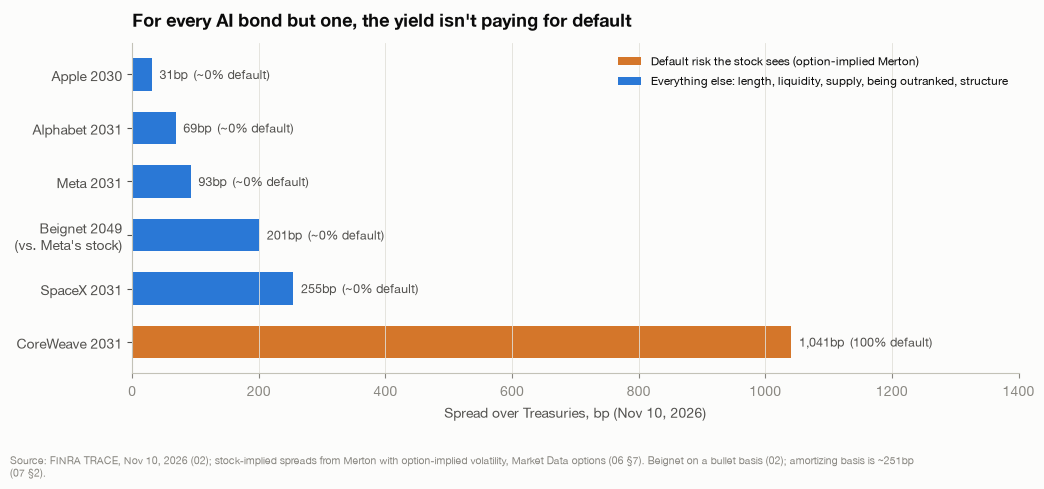

post says,data,low,high,ok
Apple/Alphabet/Meta/Beignet ~0% default,0.00649,0,0.01,True
SpaceX ~1bp of ~255bp,1.16,0,1.5,True
CoreWeave all default,1,0.99,1,True


In [9]:
rows = [('Apple', 'Apple 2030'), ('Alphabet', 'Alphabet 2031'), ('Meta', 'Meta 2031'),
        ('Meta (SPV)', 'Beignet 2049\n(vs. Meta\'s stock)'), ('SpaceX', 'SpaceX 2031'), ('CoreWeave', 'CoreWeave 2031')]
sp = pd.DataFrame([{'label': lab, 'spread': evb.loc[iss, 'bond spread'],
                    'stock': iv['Meta' if iss == 'Meta (SPV)' else iss]} for iss, lab in rows])
sp['default'] = sp[['spread', 'stock']].min(axis=1)
sp['other'] = sp.spread - sp.default
display(sp.round(1))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
y = np.arange(len(sp))[::-1]
ax.barh(y, sp.default, color=EQUITY, height=0.6, label='Default risk the stock sees (option-implied Merton)')
ax.barh(y, sp.other, left=sp.default, color=BOND, height=0.6, label='Everything else: length, liquidity, supply, being outranked, structure')
for yi, r in zip(y, sp.itertuples()):
    share = r.default / r.spread
    ax.text(r.spread + 12, yi, f'{r.spread:,.0f}bp' + (f'  ({share:.0%} default)' if share > 0.02 else '  (~0% default)'),
            va='center', fontsize=9, color=INK2)
ax.set_yticks(y, sp.label)
ax.set_xlim(0, 1400); ax.grid(axis='y', visible=False)
ax.set_xlabel(f'Spread over Treasuries, bp ({pd.Timestamp(AS_OF):%b %-d, %Y})')
ax.legend(loc='upper right', fontsize=8.5)
ax.set_title("For every AI bond but one, the yield isn't paying for default", pad=12)
source_note(fig, f'Source: FINRA TRACE, {pd.Timestamp(AS_OF):%b %-d, %Y} (02); stock-implied spreads from Merton with option-implied volatility, Market Data options (06 §7). '
                 'Beignet on a bullet basis (02); amortizing basis is ~251bp (07 §2).')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(Path('charts') / '00_what_the_spread_pays_for.png', dpi=200, bbox_inches='tight')
plt.show()

check([('Apple/Alphabet/Meta/Beignet ~0% default', (sp.default / sp.spread).iloc[:4].max(), 0, 0.01),
       ('SpaceX ~1bp of ~255bp', sp.loc[4, 'default'], 0, 1.5),
       ('CoreWeave all default', sp.loc[5, 'default'] / sp.loc[5, 'spread'], 0.99, 1.0)])

**What this shows** (`charts/00_what_the_spread_pays_for.png`):
- **Apple, Alphabet, Meta:** the stocks see essentially no chance of default within 5 years, so all 31–93bp is "everything else". You're paid for lending long and for the wave of new AI bonds, not for risk of loss.
- **Beignet:** ~201bp, against a Meta stock that sees ~0bp. The yield isn't pricing Meta's credit. It's pricing the structure: the 4-year lease, the conditional guarantee, and a 144A bond few people can buy (07).
- **SpaceX:** ~255bp, with the stock seeing ~1bp. With a ~$1.9T market cap against $38B of debt, the equity can't plausibly be wiped out. The spread pays for being outranked by the GPU lenders who come next (06 §5–6).
- **CoreWeave:** the only bond where the yield is default risk, and the stock sees at least as much (~1,136bp vs. the bond's ~1,041bp). What's left to argue about is *when* (06 §8: options see the next year as the worst; bonds don't) and *at what GPU price* (08 §3).

**For the post:** this is the closing chart. It answers research question 6, "are these bonds mispriced relative to what you own?" Mostly no. The market isn't fooled, but what it's charging for isn't what the headlines say.

## 9 · For entertainment: how do you bet on a view, and how does a reader do it without the bond?

**Post claims** [09 §9; options at the Nov 9 close, bonds at Nov 10 TRACE last trades; P&L to the Jan 19, 2029 option expiry, per $10,000 of bond face (or the same cash in Treasuries); "yield" = yearly return on the cash put up]:
- **Prices:** CoreWeave $49.00, SpaceX $142.12 (Nov 9); CoreWeave 2030 notes 85.50 (14.6%), SpaceX 2031s 92.74 (7.2%); Treasuries ~4.6% to Jan 2029.
- **Build your own bond:** CoreWeave, Treasuries + seven sold $20/$10 put spreads: collects $2,170, +$3,050 (14.9% a year) above $20, break-even ~$16 (~44% odds), worst ~−$3,950. SpaceX, two sold $60/$30 spreads: collects $806, +$1,761 (8.2%) above $60, break-even ~$51 (~22% odds), worst ~−$4,240.
- **Trade 1** (2030 notes + $20 put − $90 call): call $14.45, put $6.95, net $750. Dilution rescue +$4,013 (19.2%) vs. bond alone +$3,263 (15.9%); without the put ~$4,700. Nothing changes +$3,586 (17.3%) vs. +$2,837 (14.0%). Default +$131 vs. −$2,519. Trails the bond above ~$104; loses money above ~$126 (~13% odds).
- **Trade 2** (iron condor): collects $1,800; +$2,680 (13.2%) between ~$10 and $90; break-evens ~$7 and ~$103; default −$2,320; shortage −$3,320; worst ~−$6,300.
- **Trade 3** (seagull): options $460 vs. $955 of Treasury interest; +$5,418 (22.3%) at $350B; +$495 (2.3%) if nothing changes; worst ~−$4,000; break-even ~$255.
- **Trade 4:** $100 put $1,760, $100/$25 spread $1,680; worst ~−$660 (bond) / −$725 (Treasuries, −3.1% a year); ~$6,700–7,100 (24–25%) at $350B; distress +$6,800 vs. +$3,600.
- **Trade 5** (2031 notes − $200 call, $3,080): 20.0% a year if nothing changes; loses above ~$246 (~17% odds); −$5,200 at $300.
- **Trade 6** (Treasuries + $150/$295 call spread, $3,075): up to $14,500 payout, +$12,380 (37.2%); break-even ~$171; worst −$2,120 (−8.2%).
- **Summary table:** bonds alone if nothing changes: CoreWeave +$2,837 (14.0%), SpaceX +$1,487 (7.0%), worst −$2,519 / −$4,099 in a default.


In [10]:
pt = pd.read_csv('data/post_trades.csv').set_index(['trade', 'version', 'scenario'])        # 09 §9: the post's trades
pp = pd.read_csv('data/post_trade_profiles.csv').set_index(['trade', 'version'])
v = lambda trade, i=0: pp.loc[trade].index[i]                                                   # version label, in 09 §9's order
P = lambda trade, sc, col='pnl', i=0: pt.loc[(trade, v(trade, i), sc), col]
Q = lambda trade, col, i=0: pp.loc[(trade, v(trade, i)), col]
CW, SX, B = 'CRWV', 'SPCX', 'Just the bond'
bond = lambda tk, sc: trades.loc[(tk, B, sc)]
T09 = (pd.Timestamp('2029-01-19') - pd.Timestamp(tq.as_of.max())).days / 365.25
yr = lambda pnl, cap: 100 * ((1 + pnl / cap) ** (1 / T09) - 1)
cw_cash, sx_cash = 100 * tq.loc['CRWV_9.25_2030', 'price'], 100 * tq.loc['SPCX_5.350_2031', 'price']
check([("options as of Nov 9", int(pd.Timestamp(tq.as_of.max()).strftime('%m%d')), 1109, 1110),
       ('CoreWeave 2030 yield 14.6%', tq.loc['CRWV_9.25_2030', 'yield_pct'], 14.55, 14.7), ('SpaceX 2031 yield 7.2%', tq.loc['SPCX_5.350_2031', 'yield_pct'], 7.15, 7.25),
       ('Treasuries ~4.6% to Jan 2029', treasury_yield(pd.Timestamp(tq.as_of.max()), T09), 4.5, 4.65),
       ('build CW collects $2,170', Q('build', 'options cash at entry'), 2165, 2175), ('build CW +$3,050', Q('build', 'if nothing changes'), 3045, 3055),
       ('build CW 14.9%/yr', 100 * Q('build', 'yearly if nothing changes'), 14.85, 14.95), ('build CW worst ~-$3,950', Q('build', 'worst with a default'), -4000, -3900),
       ('build SX collects $806', Q('build', 'options cash at entry', 1), 802, 810), ('build SX +$1,761', Q('build', 'if nothing changes', 1), 1757, 1765),
       ('build SX 8.2%/yr', 100 * Q('build', 'yearly if nothing changes', 1), 8.15, 8.3), ('build SX worst ~-$4,240', Q('build', 'worst with a default', 1), -4290, -4190),
       ('1: dilution +$4,013', P('trade1', 'Dilution rescue'), 4009, 4017), ('1: 19.2%/yr', 100 * P('trade1', 'Dilution rescue', 'yearly return'), 19.1, 19.25),
       ('bond alone dilution +$3,263', bond(CW, 'Dilution rescue'), 3259, 3267), ('bond alone 15.9%/yr', yr(bond(CW, 'Dilution rescue'), cw_cash), 15.8, 15.95),
       ('without the put ~$4,700', trades.loc[(CW, '1. Dilution, not default: bond + sell 1 $90 call', 'Dilution rescue')], 4650, 4750),
       ('1: nothing changes +$3,586', P('trade1', 'Muddle through'), 3582, 3590), ('1: 17.3%/yr', 100 * P('trade1', 'Muddle through', 'yearly return'), 17.25, 17.35),
       ('bond alone muddle +$2,837', bond(CW, 'Muddle through'), 2833, 2841), ('bond alone 14.0%/yr', yr(bond(CW, 'Muddle through'), cw_cash), 13.9, 14.05),
       ('1: default +$131', P('trade1', 'Glut and default'), 127, 135), ('bond alone default -$2,519', bond(CW, 'Glut and default'), -2523, -2515),
       ('1: net credit $750', Q('trade1', 'options cash at entry'), 748, 752),
       ('2: collects $1,800', Q('trade2', 'options cash at entry'), 1795, 1805), ('2: +$2,680', P('trade2', 'Muddle through'), 2676, 2684),
       ('2: 13.2%/yr', 100 * P('trade2', 'Muddle through', 'yearly return'), 13.15, 13.25), ('2: default -$2,320', P('trade2', 'Glut and default'), -2324, -2316),
       ('2: shortage -$3,320', P('trade2', 'Shortage lasts'), -3324, -3316), ('2: worst ~-$6,300', Q('trade2', 'max loss (repaid)'), -6350, -6250),
       ('3: options -$460', Q('trade3', 'options cash at entry'), -465, -455), ('3: $350B +$5,418', P('trade3', 'Worth $350B, solvent'), 5414, 5422),
       ('3: 22.3%/yr', 100 * P('trade3', 'Worth $350B, solvent', 'yearly return'), 22.25, 22.35), ('3: +$495', P('trade3', 'Muddle through'), 491, 499),
       ('3: 2.3%/yr', 100 * P('trade3', 'Muddle through', 'yearly return'), 2.25, 2.35), ('3: worst ~-$4,000', Q('trade3', 'max loss (repaid)'), -4050, -3950),
       ('4: worst ~-$660 (bond version)', pt.loc['trade4'].xs(v('trade4', 0)).pnl.min(), -700, -620), ('4: worst ~-$725 (Treasury version)', Q('trade4', 'max loss (repaid)', 1), -730, -720),
       ('4: -3.1%/yr', 100 * P('trade4', 'Muddle through', 'yearly return', 1), -3.15, -3.05),
       ('4: $350B ~$6,700 (Treasury)', P('trade4', 'Worth $350B, solvent', 'pnl', 1), 6650, 6750), ('4: $350B ~$7,100 (bond)', P('trade4', 'Worth $350B, solvent'), 7050, 7150),
       ('4: 24-25%/yr', 100 * P('trade4', 'Worth $350B, solvent', 'yearly return', 1), 24, 25.4), ('4: distress +$6,800 (Treasury)', P('trade4', 'Distress', 'pnl', 1), 6750, 6850),
       ('4: distress +$3,600 (bond)', P('trade4', 'Distress'), 3550, 3700),
       ('5: 20.0%/yr', 100 * P('trade5', 'Muddle through', 'yearly return'), 19.95, 20.05), ('5: -$5,200 at $300', P('trade5', 'AI wins'), -5250, -5100),
       ('6: costs $3,075', Q('trade6', 'options cash at entry'), -3080, -3070), ('6: +$12,380', Q('trade6', 'max gain (repaid)'), 12376, 12384),
       ('6: 37.2%/yr', 100 * P('trade6', 'AI wins', 'yearly return'), 37.15, 37.25), ('6: worst -$2,120', Q('trade6', 'max loss (repaid)'), -2124, -2116),
       ('6: -8.2%/yr', 100 * P('trade6', 'Muddle through', 'yearly return'), -8.25, -8.15),
       ('SpaceX bond alone +$1,487', bond(SX, 'Muddle through'), 1483, 1491), ('SpaceX bond 7.0%/yr', yr(bond(SX, 'Muddle through'), sx_cash), 6.95, 7.05),
       ('SpaceX bond default -$4,099', bond(SX, 'Distress'), -4103, -4095)])
assert [Q(k, 'break-even(s)') for k in ['build', 'trade1', 'trade3', 'trade6']] == ['$16', '$126', '$255', '$171'] \
       and Q('build', 'break-even(s)', 1) == '$51' and Q('trade2', 'break-even(s)') == '$7, $103', 'break-evens changed: update the post'


post says,data,low,high,ok
options as of Nov 9,1.11e+03,1.11e+03,1.11e+03,True
CoreWeave 2030 yield 14.6%,14.6,14.6,14.7,True
SpaceX 2031 yield 7.2%,7.2,7.15,7.25,True
Treasuries ~4.6% to Jan 2029,4.56,4.5,4.65,True
"build CW collects $2,170",2.17e+03,2.16e+03,2.18e+03,True
"build CW +$3,050",3.05e+03,3.04e+03,3.06e+03,True
build CW 14.9%/yr,14.9,14.8,14.9,True
"build CW worst ~-$3,950",-3.95e+03,-4e+03,-3.9e+03,True
build SX collects $806,806,802,810,True
"build SX +$1,761",1.76e+03,1.76e+03,1.76e+03,True


![Can you build the bond from Treasuries and options? (09 §2)](charts/09_build_your_own_bond.png)
*`charts/09_build_your_own_bond.png`: Can you build the bond from Treasuries and options? (09 §2)*

![CoreWeave: what each bet makes or loses by Jan 2029 (09 §3-4)](charts/09_coreweave_trades.png)
*`charts/09_coreweave_trades.png`: CoreWeave: what each bet makes or loses by Jan 2029 (09 §3-4)*

![CoreWeave without the 144A bond: what each reader trade pays (09 §4)](charts/09_coreweave_payoffs.png)
*`charts/09_coreweave_payoffs.png`: CoreWeave without the 144A bond: what each reader trade pays (09 §4)*

![SpaceX: what each bet makes or loses by Jan 2029 (09 §5-6)](charts/09_spacex_trades.png)
*`charts/09_spacex_trades.png`: SpaceX: what each bet makes or loses by Jan 2029 (09 §5-6)*

![SpaceX without the 144A bond: what each reader trade pays (09 §6)](charts/09_spacex_payoffs.png)
*`charts/09_spacex_payoffs.png`: SpaceX without the 144A bond: what each reader trade pays (09 §6)*

![How to build the trades without a 144A bond: add the legs (09 §7)](charts/09_how_to_build_it.png)
*`charts/09_how_to_build_it.png`: How to build the trades without a 144A bond: add the legs (09 §7)*

**The post's per-trade payoff charts (09 §9):**

![Build your own bond](charts/09_post_build.png)
*`charts/09_post_build.png`*

![Trade 1](charts/09_post_trade1.png)
*`charts/09_post_trade1.png`*

![Trade 2](charts/09_post_trade2.png)
*`charts/09_post_trade2.png`*

![Trade 3](charts/09_post_trade3.png)
*`charts/09_post_trade3.png`*

![Trade 4](charts/09_post_trade4.png)
*`charts/09_post_trade4.png`*

![Trade 5](charts/09_post_trade5.png)
*`charts/09_post_trade5.png`*

![Trade 6](charts/09_post_trade6.png)
*`charts/09_post_trade6.png`*

## Findings, by section
1. **§1:** IG is calm (81 → 91bp since Aug 22, mid-range for 3 years); junk widened, worst at CCC (~1,040 → ~1,310bp). *Corrected 02 and the plan on Oct 31, which said IG was near lows and BB/B barely moved.*
2. **§2:** "default spread" is estimated two ways: from the bond (credit triangle, an upper bound) and from the stock (Merton). At ~5 years only SpaceX (~7.2%) and CoreWeave (~15%) yield much above Treasuries (~4.7%). Every bond's price implies more defaults than its rating's history, even Apple's (~20–37×), so the post compares within ratings or the same bond over time.
3. **§3:** Apple behaves like a control (−36bp vs. AA, tighter since issue); Alphabet isn't one (borrowed ~$52B and sold stock).
4. **§4:** Meta's spread isn't default (~0.6bp stock-implied vs. ~93bp); its long end widened +51bp since issue.
5. **§5:** Beignet is ~330× Meta's stock-implied odds and slightly tighter vs. its bucket since issue; you're paid for the structure, and that premium (~110–125bp over Meta) has narrowed.
6. **§6:** SpaceX at ~7.2%: $139 vs. $125 by 2031, worth it above ~80–89% confidence. You're buying GPU scarcity, continued access to new money, and a Starlink/stock backstop that is economic, not legal. Cheapened most since issue (+108bp).
7. **§7:** CoreWeave at ~15%: $186 vs. $125, worth it above ~40–60% odds of full repayment. You're buying GPU scarcity lasting to 2031. Selling stock backs the 2028 maturities (~26% of the company at $48.73) but shrinks as the stock falls with GPU prices (~59% after a 75% fall), so it's a second claim on the same outcome. Priced like CCC; the stock sees about as much default risk as the bonds pay for (~1,136 vs. ~1,041bp). After Q3 (10 §8–9): new contracts at $20–25M/MW and the GPUs' second life cover CoreWeave, Inc.'s ~$21B of bonds due 2030–33 if nothing more is signed; the old contracts alone don't.
8. **§8:** for every rung but CoreWeave, the yield isn't paying for default (`00_what_the_spread_pays_for.png`).
9. **§9:** trades for conviction (09: Nov 9 options, Nov 10 TRACE), each with a payoff chart and a yield on the cash put up (09 §9). Readers can build a CoreWeave bond from Treasuries + sold $20/$10 put spreads (~14.9% vs. 14.6%), but it's a stock bet (~44% odds of a loss); a SpaceX build only beats the bond's 7.2% by insuring a ~60% fall. Trade 1 (notes + $20 put − $90 call) ~17% a year if nothing changes; the iron condor ~13%; SpaceX notes − $200 call ~20%; the seagull ~2.3%.

## Caveats
- Prices are single TRACE last trades on Nov 10 and option closes on Nov 9; the 144A bonds trade thinly.
- 07 doesn't write a handoff file, and 08 only writes §5's (`data/equity_backstop.csv`), so their other numbers are listed in §5–7 as checked against the notebook outputs, not re-computed here. Re-check them by eye after re-running 07 or 08.
- The SPV spread in §8 is on a bullet basis (02); 07's amortizing basis is wider.
- Company financials are still Q2 (Jun 30) except where noted; CoreWeave's Q3 10-Q wasn't filed at the Nov 10 refresh.

## Open items (tracked in `research_plan.md`)
- CoreWeave's Q3 10-Q: refresh `issuers.csv`, 06 and 08, then re-run this notebook.
- Apollo lease pricing (SpaceX), expected at the year-end close.
- Who the Meta SPV guarantee actually pays; the offering memoranda aren't public.
- Notebook 04 (GPU collateral) isn't built; 08 §3 covers the post's need.
